# Inspect swing-shape clustering

- `swings` - competitive-swing model table (`data/swings_model.parquet`)
- `assign` - per-swing cluster assignment (`play_id, batter_id, cluster, resp_max`)
- `summary` - per-(batter, cluster) raw-unit centroids + usage weight
- `rep` - per-batter repertoire (`k, bic, effective_shapes`, ...)
- `swc` - `swings` left-joined with `assign` (per-swing frame with features + context + value + cluster)

Helpers: `SHAPE` (5 clustering features), `RAW_SHAPE` (unmirrored), `by_name(s)` to find a batter_id.

In [1]:
library(arrow)
library(tidyverse)
library(ggthemes)
library(IRdisplay)

options(repr.plot.width = 14, repr.plot.height = 6, repr.plot.res = 150)

ROOT  <- if (dir.exists(file.path(getwd(), "data"))) getwd() else dirname(getwd())
DATA  <- file.path(ROOT, "data")
PLOTS <- file.path(ROOT, "results", "plots")
dir.create(PLOTS, recursive = TRUE, showWarnings = FALSE)

FT_THEME <- theme_fivethirtyeight() +
  theme(axis.title        = element_text(),
        axis.text         = element_text(size = 10),
        panel.background  = element_rect(fill = "white", color = NA),
        plot.background   = element_rect(fill = "white", color = NA),
        legend.background = element_rect(fill = "white", color = NA),
        strip.text        = element_text(size = 12, face = "bold"),
        plot.title        = element_text(size = 16, face = "bold"))

plot_path <- function(name) {
  sub <- if (grepl("^swing_cards",   name)) "swing_cards"
    else if (grepl("^usage_heatmap", name)) "usage_heatmap"
    else if (grepl("^repertoire",    name)) "repertoire"
    else if (grepl("^(swingplus|shape_breakdown)", name)) "swing_plus"
    else "predictiveness"
  d <- file.path(PLOTS, sub)
  dir.create(d, recursive = TRUE, showWarnings = FALSE)
  file.path(d, name)
}

SHAPE     <- c("swing_path_tilt","swing_length","bat_speed","vert_attack_angle","horz_attack_angle_pull")
RAW_SHAPE <- c("swing_path_tilt","swing_length","bat_speed","vert_attack_angle","horz_attack_angle")
cat(sprintf("data dir:  %s\nplots dir: %s\n", DATA, PLOTS))

Warning message:
“package ‘arrow’ was built under R version 4.4.3”



Attaching package: ‘arrow’




The following object is masked from ‘package:utils’:

    timestamp




Warning message:
“package ‘dplyr’ was built under R version 4.4.3”


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   4.0.1     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ lubridate::duration() masks arrow::duration()
✖ dplyr::filter()       masks stats::filter()
✖ dplyr::lag()          masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


data dir:  /Users/theoauyeung/Documents/swing_repertoire/data
plots dir: /Users/theoauyeung/Documents/swing_repertoire/results/plots


In [2]:
swings     <- read_parquet(file.path(DATA, "swings_model.parquet"))
assign     <- read_parquet(file.path(DATA, "cluster_assignments.parquet"))
clust_summ <- read_parquet(file.path(DATA, "cluster_summary.parquet"))
rep        <- read_parquet(file.path(DATA, "batter_repertoire.parquet"))

for (nm in c("swings", "assign", "clust_summ", "rep")) {
  d <- get(nm)
  cat(sprintf("%-12s %d × %d\n", nm, nrow(d), ncol(d)))
}

swings       795723 × 40
assign       780328 × 5
clust_summ   1592 × 12
rep          703 × 11


In [3]:
# per-swing analysis frame: features + context + value + assigned cluster
swc <- swings |>
  inner_join(assign |> select(play_id, cluster, resp_max), by = "play_id")
cat(sprintf("swc  %d × %d\n", nrow(swc), ncol(swc)))

by_name <- function(s) {
  rep[grepl(s, rep$batter_full_name, ignore.case = TRUE), ]
}

swc  780328 × 42


In [4]:
head(rep)
head(clust_summ)
head(swc)

batter_id,batter_stand,batter_full_name,label,n_swings,k,bic,min_weight,min_comp_n,usage_entropy,effective_shapes
<int>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>
444482,L,David Peralta,David Peralta,500,2,5366.4,0.4940,247,0.693,2.00
453568,L,Charlie Blackmon,Charlie Blackmon,817,3,8797.7,0.1151,94,0.963,2.62
455117,R,Martín Maldonado,Martín Maldonado,449,2,4969.0,0.4878,219,0.693,2.00
456781,R,Donovan Solano,Donovan Solano,888,2,9747.7,0.4989,443,0.693,2.00
457705,R,Andrew McCutchen,Andrew McCutchen,1906,2,21290.5,0.2508,478,0.563,1.76
457759,R,Justin Turner,Justin Turner,1280,2,14115.1,0.3891,498,0.668,1.95


batter_id,batter_stand,batter_full_name,label,cluster,n,weight,swing_path_tilt_mean,swing_length_mean,bat_speed_mean,vert_attack_angle_mean,horz_attack_angle_mean
<int>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
444482,L,David Peralta,David Peralta,0,253,0.5060,29.111,6.521,69.200,-0.704,12.771
444482,L,David Peralta,David Peralta,1,247,0.4940,32.766,7.761,72.265,11.703,-14.840
453568,L,Charlie Blackmon,Charlie Blackmon,0,409,0.5006,34.937,7.518,67.082,11.517,-10.008
453568,L,Charlie Blackmon,Charlie Blackmon,1,314,0.3843,26.807,6.787,67.938,7.602,-0.437
453568,L,Charlie Blackmon,Charlie Blackmon,2,94,0.1151,28.905,6.200,60.641,0.868,6.186
455117,R,Martín Maldonado,Martín Maldonado,0,230,0.5122,29.586,6.942,69.948,8.567,5.890


play_id,game_pk,game_date,game_year,batter_id,batter_full_name,batter_stand,pitcher_id,pitcher_throws,balls,⋯,sz_bot,height,swing_path_tilt,swing_length,bat_speed,vert_attack_angle,horz_attack_angle,horz_attack_angle_pull,cluster,resp_max
<chr>,<int>,<date>,<int>,<int>,<chr>,<chr>,<int>,<chr>,<int>,⋯,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
001848c7-9251-4b7e-8311-8679799076c1,745408,2024-06-06,2024,444482,David Peralta,L,677944,R,0,⋯,1.69,73,38.5906,7.4,69.4,3.67121,-9.17984,9.17984,1,0.729
0168c81f-8927-4514-8f83-38b5514293fd,746515,2024-08-17,2024,444482,David Peralta,L,664875,R,0,⋯,1.69,73,25.2650,7.9,62.6,7.26082,-8.65910,8.65910,1,1.000
033e01bc-7bc6-42e1-8712-8b2264ff048d,745372,2024-09-07,2024,444482,David Peralta,L,657277,R,2,⋯,1.69,73,38.4268,8.1,70.3,9.30411,-11.97710,11.97710,1,0.998
0377c827-08cd-4744-831f-e044991b30ce,746714,2024-05-23,2024,444482,David Peralta,L,608371,R,0,⋯,1.69,73,29.7084,7.0,69.4,3.23382,8.27273,-8.27273,0,0.784
03969283-ba94-4433-b1ce-ab980b92a021,746938,2024-06-30,2024,444482,David Peralta,L,686580,R,2,⋯,1.69,73,35.3725,8.4,74.1,17.21380,-22.27910,22.27910,1,0.999
03b60862-cb47-450d-aade-c2b175a8b88c,746610,2024-07-21,2024,444482,David Peralta,L,671922,R,1,⋯,1.69,73,36.7489,6.7,73.7,-2.93741,4.72477,-4.72477,0,0.856


## Luis Arraez Inspection 

5 Unique Swing Shapes - What Differentiates Each

In [5]:
ex   <- clust_summ |> filter(grepl("Arraez", batter_full_name, ignore.case = TRUE))
cols <- c("batter_full_name", "cluster", "n", "weight",
          paste0(RAW_SHAPE, "_mean"))
ex |> select(all_of(cols)) |> arrange(cluster) |> print(n = Inf)

# A tibble: 6 × 9
  batter_full_name cluster     n weight swing_path_tilt_mean swing_length_mean
  <chr>              <int> <int>  <dbl>                <dbl>             <dbl>
1 Luis Arraez            0   738 0.266                  36.4              6.10
2 Luis Arraez            1   600 0.216                  33.8              5.88
3 Luis Arraez            2   511 0.184                  33.8              4.88
4 Luis Arraez            3   386 0.139                  40.3              5.51
5 Luis Arraez            4   330 0.119                  48.2              6.39
6 Luis Arraez            5   215 0.0773                 36.6              6.85
# ℹ 3 more variables: bat_speed_mean <dbl>, vert_attack_angle_mean <dbl>,
#   horz_attack_angle_mean <dbl>


## Swing-shape cards (Baseball-Savant style)

| column | what it shows | source metric |
|---|---|---|
| **Attack angle** | vertical direction of the sweet spot at contact (red arrow vs flat) | `vert_attack_angle` |
| **Attack direction** | top-down heading in the hitter's real field orientation — the arrow leans toward their **pull** field (RHH pull = screen-left/LF, LHH pull = screen-right/RF), with the PULL/OPPO labels flipped to match handedness | `horz_attack_angle_pull` (pull frame; screen-flipped for LHH) |
| **Swing tilt** | plane tilt from flat (0°) toward steep | `swing_path_tilt` |
| **Bat speed** | mph vs the MLB-average tick | `bat_speed` |

In [ ]:
REGEN <- FALSE
if (REGEN) {
  system2("/usr/bin/env", args = c("python3", "src/swing_cards.py"), wait = TRUE)
}
for (png in c("swing_cards_arraez.png", "swing_cards_judge.png")) {
  p <- plot_path(png)
  if (file.exists(p)) IRdisplay::display_png(file = p)
  else cat(sprintf("Not found: %s\n", p))
}

## Cluster usage by game state (heatmap)

`usage_heatmap(name)` — pass any hitter's name (substring match). Each cell is **P(cluster | game state)**: within a situation, the share of that hitter's swings falling in each shape (columns sum to 100%).

In [ ]:
REGEN <- FALSE
if (REGEN) {
  system2("/usr/bin/env", args = c("python3", "src/swing_cards.py", "--heatmap"),
          wait = TRUE)
}
for (png in c("usage_heatmap_arraez.png", "usage_heatmap_judge.png")) {
  p <- plot_path(png)
  if (file.exists(p)) IRdisplay::display_png(file = p)
  else cat(sprintf("Not found: %s\n", p))
}

## Archetype lexicon — eyeballing the vocabulary

The per-batter clusters are bare indices. Layer 1 (`src/swing_label.py`) maps every unit-cluster onto **3 league archetypes**: **Level Oppo / Level Center / Uppercut Pull**. After the handedness fix (pull frame corrected — see below), MLB swing geometry sits on a **level-oppo ↔ uppercut-pull diagonal** (uppercut swings are pull-side), so BIC lands on 3, not a 2×2. `bat_speed` is a **descriptor, not a defining axis**.

Three checks below:
1. **Bat speed vs uppercut** — the correlation motivating the descriptor choice: effort rises with lift, so `bat_speed` is partly redundant with `vert_attack_angle`.
2. **`archetype_map(name)`** — any hitter's shapes on the league grid (x = pull frame, **+ = pull for both hands**); bubble = usage, label = cluster · bat speed.
3. **Collision curve** — a 3-word vocabulary can't uniquely name every shape of a multi-shape hitter, so labels saturate; multi-shape hitters lean on Layer 2 (delta-vs-primary + the situational tag) to separate same-label shapes.

In [8]:
arch    <- read_parquet(file.path(DATA, "shape_archetypes.parquet"))
lexicon <- read_parquet(file.path(DATA, "archetype_lexicon.parquet"))

ARCH_PAL   <- c("Level Oppo" = "#7EA6D6", "Level Center" = "#d8b483", "Uppercut Pull" = "#e23b3b")
ARCH_ORDER <- intersect(c("Level Oppo", "Level Center", "Uppercut Pull"),
                        unique(arch$archetype_name))
print(lexicon)

# A tibble: 3 × 8
  archetype archetype_name n_shapes  tilt   len   vaa haa_pull bat_speed
      <int> <chr>             <int> <dbl> <dbl> <dbl>    <dbl>     <dbl>
1         0 Level Oppo          573  29.6  6.8   4.83    -7.61      69.4
2         1 Uppercut Pull       573  33.4  8.01 18.1     16.3       71.4
3         2 Level Center        446  33.5  6.93  5.59    -5.61      70.0


## Repertoire size — distribution across the cohort

How many distinct swing shapes each `(batter, stand)` unit carries: post-merge **k** (a hard count) and **effective_shapes** (usage-weighted `exp(entropy)`, discounting rarely-used shapes).

Saved → /Users/theoauyeung/Documents/swing_repertoire/results/plots/repertoire/repertoire_size_distribution.png


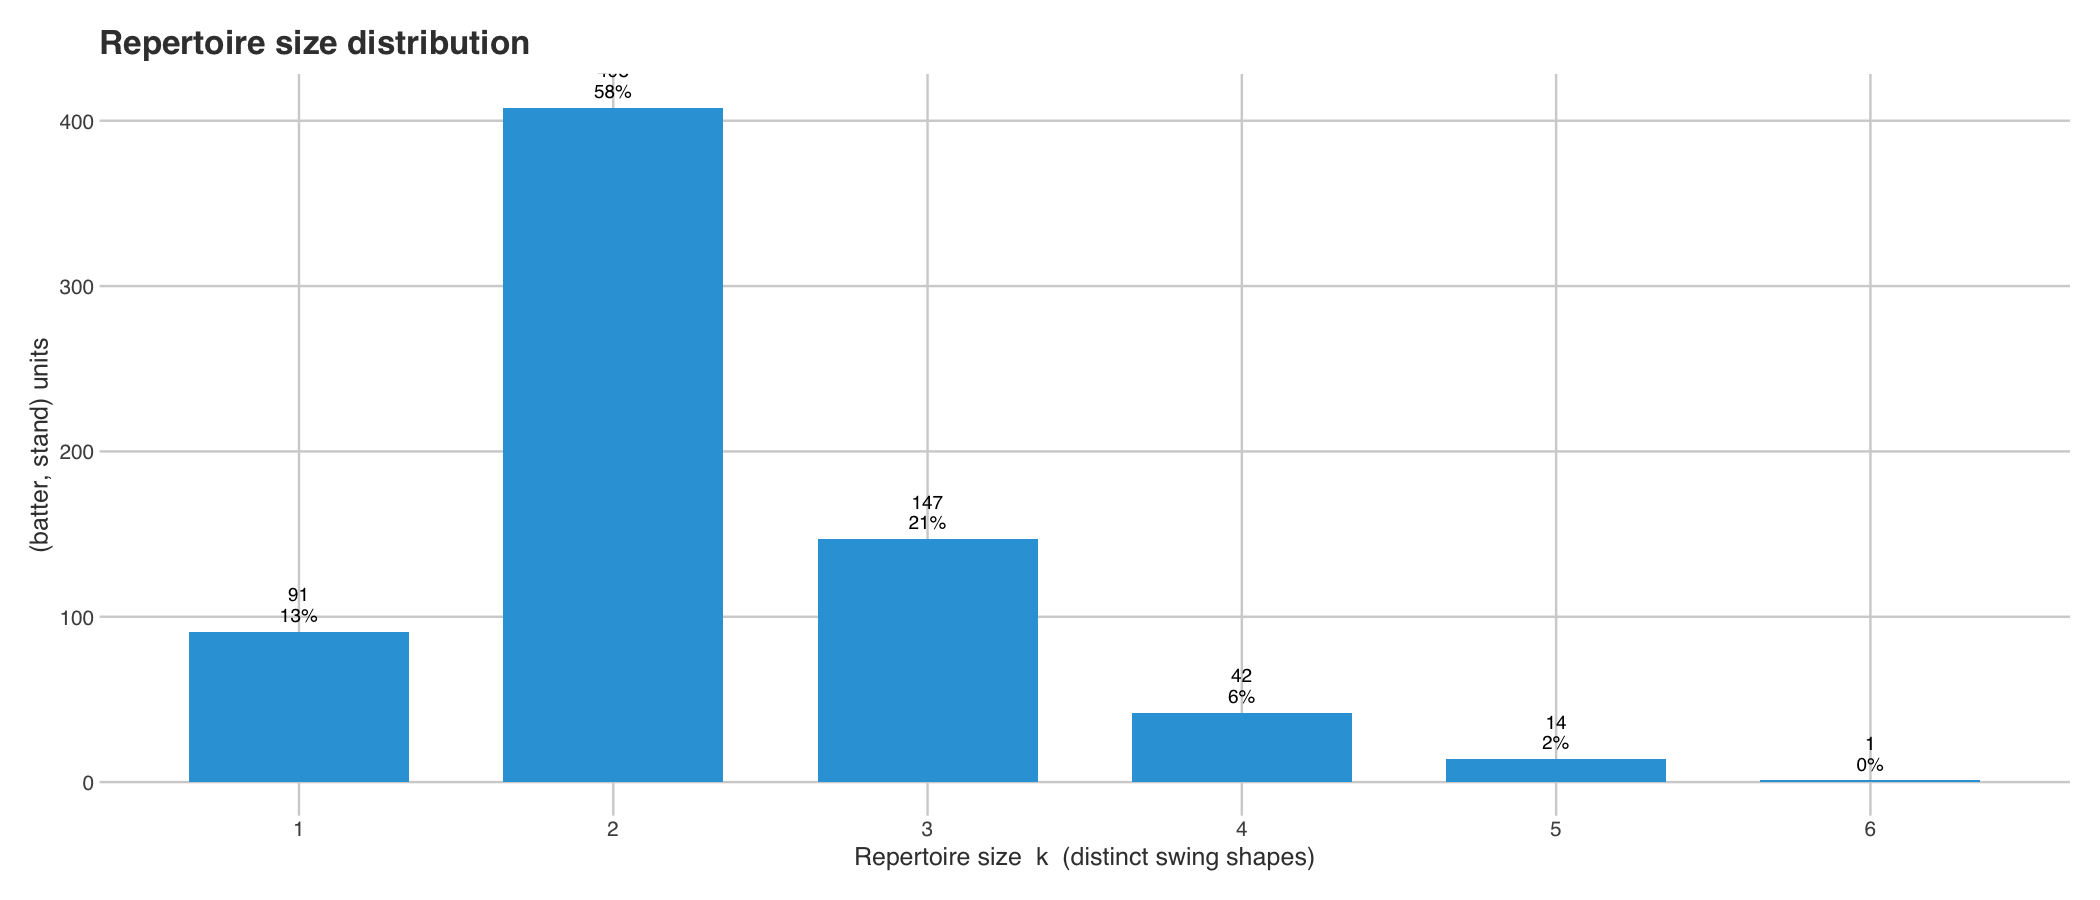

In [9]:
kc <- rep |>
  count(k, name = "n_units") |>
  arrange(k) |>
  mutate(pct   = n_units / sum(n_units) * 100,
         label = sprintf("%d\n%d%%", n_units, round(pct)))

plt <- ggplot(kc, aes(x = k, y = n_units)) +
  geom_col(fill = "#30a2da", width = 0.7) +
  geom_text(aes(label = label), vjust = -0.3, size = 3.2, lineheight = 0.9) +
  scale_x_continuous(breaks = kc$k) +
  labs(title = "Repertoire size distribution",
       x = "Repertoire size  k  (distinct swing shapes)",
       y = "(batter, stand) units") +
  FT_THEME

out <- plot_path("repertoire_size_distribution.png")
ggsave(out, plt, width = 8, height = 5, dpi = 130)
print(plt)
cat(sprintf("Saved → %s\n", out))